# FORESEE Models: Heavy Neutral Leptons (HNLs)

## Load Libraries 

In [1]:
import numpy as np
import sys
import os
src_path = "../../../"
sys.path.append(src_path)
src_path = "../"
sys.path.append(src_path)

from src_hnl.foresee import Foresee, Utility, Model
from matplotlib import pyplot as plt

from HNLCalc import * 

## 1. Specifying the Model

Heavy Neutral Leptons, denoted by $N$, are fermionic gauge singlets that can be added as an extenstion to the standard model. These HNLs mix with the SM active neutrinos, and thus pick up couplings to the SM which are suppresed by a small mixing angle, $U_\alpha$ for $\alpha = e, \mu, \tau$. The phenomenology of these interactions can be described by the following Lagrangian: 
\begin{equation} 
\mathcal{L} \supset -{m_N} \bar{N}^c N  - \frac{1}{\sqrt{2}}g\sum_{\alpha=e,\mu,\tau} {U^*_\alpha}  W_\mu^+  \,\overline{N^c} \, \gamma^\mu l_\alpha  - \frac{1}{2\cos\theta_W}g\sum_{\alpha=e,\mu,\tau} {U^*_\alpha} Z_\mu  \overline{N^c}\, \gamma^\mu \nu_\alpha+ \text{h.c.} . 
\end{equation}

In principle, this model has four free parameters: the mass $m_N$ and the three mixing angles $U_\alpha$. In practice, however, we will therefore impose some relations between the mixing angles to reduce the number of free parameters. In particular, we define $U_\alpha = g \times V_\alpha$ with $V_\alpha= \hat{U}_\alpha$ being the normalized coupling vector, so $|V_\alpha|=1$. Using this definition, we have the HNL mass $m_N$ and the coupling parameter $g$ as free parameters. 

In [2]:
energy = "100"
modelname="HNL_100"
model = Model(modelname, path="./")

In [3]:
foresee = Foresee(path="../../../")
foresee.set_model(model=model)
masses = np.logspace(-3,1,40)

**Model Initialization:** The production and decay rates of the HNL depend not only on the choice of $m_N$ and $g$, but also $V_\alpha$. In addition, the number of production modes in sgificantly larger than in other models. To simplify the process of setting up the model we provide the class `HeavyNeutralLepton(ve, vmu, vtau)`. Here `ve`, `vmu` and `vtau` correspond to the three entries of $V_\alpha$. In the following case, we choose $V_e=1$ and $V_\mu=V_\tau=0$. We also define the generators for light/heavy hadrons. 

In [4]:
hnl = HeavyNeutralLepton(ve=1, vmu=0, vtau=0)
hnl.set_generators(
    generators_light = ['EPOSLHC'],#, 'SIBYLL', 'QGSJET'],
    generators_heavy = ["Pythia8"]#'NLO-P8','NLO-P8-Max', 'NLO-P8-Min']
)

production_channels = []
for label, pid0, pid1, br, generator, description in hnl.get_channels_2body():
    print ('include:', description)
    model.add_production_2bodydecay(
        label = label,
        pid0 = pid0,
        pid1 = pid1,
        br = br,
        generator = generator,
        energy = energy,
        nsample = 10,
    )
    production_channels.append([label, None, description])

for label, pid0, pid1, pid2,br,generator,integration,description in hnl.get_channels_3body():
    print ('include:', description)
    model.add_production_3bodydecay(
        label = label,
        pid0 = pid0,
        pid1 = pid1,
        pid2 = pid2,
        br = br,
        generator = generator,
        energy = energy,
        nsample = 10,
        integration = integration,
    )
    production_channels.append([label, None, description])

# for mass in masses:
#     foresee.get_llp_spectrum(mass=mass, coupling=1, do_plot=False, save_file=True, folder="e/")

include: $D^+ \to e^+ + N$
include: $D^- \to e^- + N$
include: $D_s^+ \to e^+ + N$
include: $D_s^- \to e^- + N$
include: $B^+ \to + e^+ + N$
include: $B^- \to + e^- + N$
include: $B_c^+ \to + e^+ + N$
include: $B_c^- \to + e^- + N$
include: $\pi^+ \to + e^+ + N$
include: $\pi^- \to + e^- + N$
include: $K^+ \to + e^+ + N$
include: $K^- \to + e^- + N$
include: $D^0 \to K^- + e^+ + N$
include: $D^0 \to K^+ + e^- + N$
include: $D^+ \to \bar{K}^0 + e^+ + N$
include: $D^- \to K^0 + e^- + N$
include: $B^+ \to \bar{D}^0 + e^+ + N$
include: $B^- \to D^0 + e^- + N$
include: $B^0 \to D^- + e^+ + N$
include: $B^0 \to D^+ + e^- + N$
include: $B^0_s \to D^-_s + e^+ + N$
include: $B^0_s \to D^+_s + e^- + N$
include: $B^+_c \to B^0 + e^+ + N$
include: $B^-_c \to \bar{B}^0 + e^- + N$
include: $B^+_c \to B^0_s + e^+ + N$
include: $B^-_c \to \bar{B}^0_s + e^- + N$
include: $K^0_S \to \pi^+ + e^- + N$
include: $K^0_S \to \pi^- + e^+ + N$
include: $K^0_L \to \pi^+ + e^- + N$
include: $K^0_L \to \pi^- + e^+

**Production:** The leptonic two body decay of a pseudoscalar meson $P \to l N$ is a dominant production mechanism for HNL's. In addition, HNLs with non-vanishing coupling to taus can be produced in two body tau decays $\tau \to M N$ with $M = \pi, K, \rho, K^*$. We can load all the non-vanishing channels using `hnl.get_channels_2body()`. 

Additionally, HNLs can be produced through three body pseudoscalar meson decay $P \to P'lN, VlN$ or through three body tau decays $\tau \to l \nu N$. The non-vanishing three body channels can likewise be loaded using `hnl.get_channels_3body()`. 

In [6]:
# model.set_ctau_1d(
#     filename=f"model/ctau/ctau.txt",
#     coupling_ref=1 
# )

# modes,finalstates,filenames = hnl.set_brs()

# model.set_br_1d(
#     modes=modes,
#     finalstates=finalstates,
#     filenames=filenames
# )

**Decay:** HNLs can decay into purely leptonic finalstates, $\nu\, l_\alpha^+ l_\beta^-$ or $\nu\nu\nu$, and Hadronic finalstates, $\nu H^0 (q\overline{q})$ or $l^\pm H^\mp (q\overline{q}')$,   with a decay width proportional to $g^2$. Since we are considering Majorana HNLs, LNV decays are included. We implemented the decay formulas given in [1905.00284](https://arxiv.org/abs/1905.00284). The function `hnl.get_br_and_ctau()` is used to generate the decay branching fractions and lifetimes and stores them in the `model/br` and `model/ctau` folders respectively. The function `hnl.set_brs()` provides the input needed to load the branching fractions into FORESEE. 

We can now initiate FORESEE with the model that we just created. 

We can see what the branching fractions look like for each of the production channels. Here we only plot the first 20 channels in 'production_channels'. 

In [7]:
# hnl.get_br_and_ctau()

## 2. Event Generation

In the following, we want to study one specific benchmark point with $m_{N}=1$ GeV and $\epsilon=1\cdot 10^{-3}$ and export events as a HEPMC file. 

First, we will produce the corresponding flux for this mass and a reference coupling $\epsilon_{ref}=1$. 

Next, let us define the configuration of the detector (in terms of position, size and luminosity). Here we choose FASER during LHC Run 3. 

In [8]:
foresee.set_detector(
    distance=1500, 
    selection="abs(x.x)<10 and abs(x.y)<10", 
    length=400, 
    luminosity=30000,
)

In [9]:
# distance, selection, length, luminosity = 1500, "abs(x.x)<10 and abs(x.y)<10", 400, 30000
# energy, setup, name = '100', "default_LLP2_", "U1_X"

For our benchmark point, let us now look at how many particle decay inside the decay volume. We also export 1000 unweighted events as a HEPMC file. 

Let us plot the resulting energy distribution

## 3. Sensitivity Reach

In the following, we will obtain the projected sensitivity for the LLP model. For this, we first define a grid of couplings and masses, and then produce the corresponding fluxes. 

We can now plot the `production rate vs mass` using the `foresee.plot_production()` function.

Let us now scan over various masses and couplings, and record the resulting number of events. Here we are iterating over various detector configurations: FASER Run 3, FASER HL-LHC, and FASER2 HL-LHC. 

In [10]:
visible_modes = [mode for mode in list(model.br_finalstate.keys()) if mode != ('nu', 'nu', 'nu')]
couplings = np.logspace(-5,0,50)

#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    couplings, _, nevents, _, _  = foresee.get_events(mass=mass, energy=energy, couplings = couplings, nsample=2, Ncast=True, N=1, folder="e/")
    list_nevents.append(nevents.T[0])
        
#save results
np.save("model/results/"+energy+"TeV_SHiP_e.npy",[masses,couplings,list_nevents])

#get reach  
list_nevents = []    
#masses = np.logspace(-2, 1, 50)
for mass in masses:
    couplings, _, nevents, _, _  = foresee.get_events(mass=mass, energy=energy, couplings = couplings, nsample=2, Ncast=True, N=2, folder="mu/")
    list_nevents.append(nevents.T[0])
        
#save results
np.save("model/results/"+energy+"TeV_SHiP_mu.npy",[masses,couplings,list_nevents])

/home/souvik/anaconda3/lib/python3.11/site-packages/numpy/lib/npyio.py:521: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr = np.asanyarray(arr)


We can now plot the results. For this, we first specify all detector setups for which we want to show result (filename in model/results directory, label, color, linestyle, opacity alpha for filled contours, required number of events).

We also want to show the branching fractions for some of the channels (name of file in model/br directory, color, line style, label, x-position, y-position).

Finally, we can plot everything using `foresee.plot_reach()`. The function `hnl.get_bounds()` is used to import existing constraints.  

/tmp/ipykernel_9752/2329122444.py:10: UserWarning: The following kwargs were not used by contour: 'clabel'
  plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)


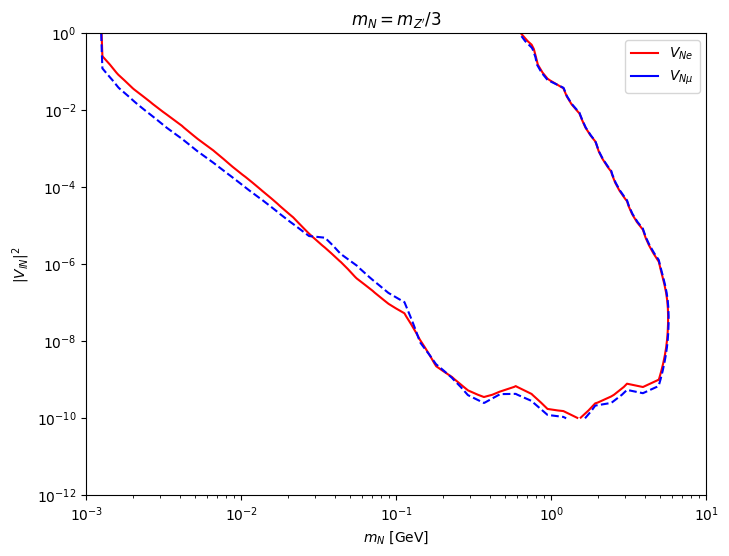

In [19]:
setups = [
    ["e"                                 ,  r"$V_{Ne}$"                , "red"      ,  "solid"   , 0., 3],
    ["mu"                                ,  r"$V_{N\mu}$"              , "blue"     ,  "dashed"   , 0., 3],
]
for setup in setups:
    filename, label, color, ls, alpha, level = setup
    masses,couplings,nsignals=np.load("model/results/100TeV_LLP2_"+filename+".npy", allow_pickle=True, encoding='latin1')
    m, c = np.meshgrid(masses, couplings**2)
    n = np.log10(np.array(nsignals).T+1e-20)
    plt.contour (m,c,n, levels=[np.log10(level)],colors=color, linestyles=ls, clabel=label)
    plt.plot([0],[0],label=label, color=color)
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel(r"$m_{N}$ [GeV]") 
    plt.ylabel(r"$|V_{lN}|^2$")
    plt.rcParams["figure.figsize"]=(8,6)
    plt.xlim(1e-3, 10)
    plt.ylim(1e-12, 1)
    plt.title(r"$m_N = m_{Z'}/3$")
plt.legend()